In [1]:
import pandas as pd
import numpy as np

In [2]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

In [3]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
test.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


In [5]:
print("Training set shape",train.shape)
print("Testing set shape",test.shape)

Training set shape (1460, 81)
Testing set shape (1459, 80)


In [6]:
train.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [7]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [8]:
train.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [9]:
train["SalePrice"].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

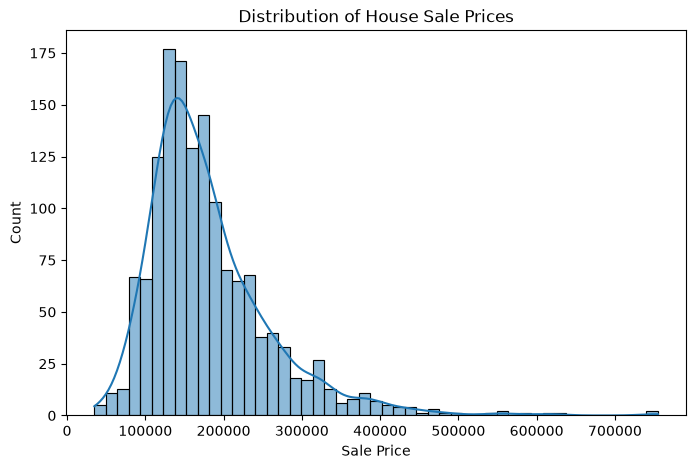

In [11]:
plt.figure(figsize=(8, 5))
sns.histplot(train["SalePrice"], kde=True)
plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price")
plt.show()

In [12]:
train.isnull().sum()

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64

In [13]:
train.duplicated().sum()

np.int64(0)

In [14]:
train.corr(numeric_only=True)

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
Id,1.000000,0.011156,-0.010601,-0.033226,-0.028365,0.012609,-0.012713,-0.021998,-0.050298,-0.005024,...,-0.029643,-0.000477,0.002889,-0.046635,0.001330,0.057044,-0.006242,0.021172,0.000712,-0.021917
MSSubClass,0.011156,1.000000,-0.386347,-0.139781,0.032628,-0.059316,0.027850,0.040581,0.022936,-0.069836,...,-0.012579,-0.006100,-0.012037,-0.043825,-0.026030,0.008283,-0.007683,-0.013585,-0.021407,-0.084284
LotFrontage,-0.010601,-0.386347,1.000000,0.426095,0.251646,-0.059213,0.123349,0.088866,0.193458,0.233633,...,0.088521,0.151972,0.010700,0.070029,0.041383,0.206167,0.003368,0.011200,0.007450,0.351799
LotArea,-0.033226,-0.139781,0.426095,1.000000,0.105806,-0.005636,0.014228,0.013788,0.104160,0.214103,...,0.171698,0.084774,-0.018340,0.020423,0.043160,0.077672,0.038068,0.001205,-0.014261,0.263843
OverallQual,-0.028365,0.032628,0.251646,0.105806,1.000000,-0.091932,0.572323,0.550684,0.411876,0.239666,...,0.238923,0.308819,-0.113937,0.030371,0.064886,0.065166,-0.031406,0.070815,-0.027347,0.790982
OverallCond,0.012609,-0.059316,-0.059213,-0.005636,-0.091932,1.000000,-0.375983,0.073741,-0.128101,-0.046231,...,-0.003334,-0.032589,0.070356,0.025504,0.054811,-0.001985,0.068777,-0.003511,0.043950,-0.077856
YearBuilt,-0.012713,0.027850,0.123349,0.014228,0.572323,-0.375983,1.000000,0.592855,0.315707,0.249503,...,0.224880,0.188686,-0.387268,0.031355,-0.050364,0.004950,-0.034383,0.012398,-0.013618,0.522897
YearRemodAdd,-0.021998,0.040581,0.088866,0.013788,0.550684,0.073741,0.592855,1.000000,0.179618,0.128451,...,0.205726,0.226298,-0.193919,0.045286,-0.038740,0.005829,-0.010286,0.021490,0.035743,0.507101
MasVnrArea,-0.050298,0.022936,0.193458,0.104160,0.411876,-0.128101,0.315707,0.179618,1.000000,0.264736,...,0.159718,0.125703,-0.110204,0.018796,0.061466,0.011723,-0.029815,-0.005965,-0.008201,0.477493
BsmtFinSF1,-0.005024,-0.069836,0.233633,0.214103,0.239666,-0.046231,0.249503,0.128451,0.264736,1.000000,...,0.204306,0.111761,-0.102303,0.026451,0.062021,0.140491,0.003571,-0.015727,0.014359,0.386420


In [15]:
%pip install fg-data-profiling

Note: you may need to restart the kernel to use updated packages.


In [16]:
from data_profiling import ProfileReport

prof = ProfileReport(train, title="Housing Price EDA")
prof.to_file("Output.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 81/81 [00:01<00:00, 42.78it/s]


KeyboardInterrupt: 

In [17]:
missing_train = train.isnull().sum()
missing_train = missing_train[missing_train > 0].sort_values(
    ascending=False
)

display(missing_train)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

In [18]:
missing_test = test.isnull().sum()
missing_test = missing_test[missing_test > 0].sort_values(
    ascending=False
)

display(missing_test)

PoolQC          1456
MiscFeature     1408
Alley           1352
Fence           1169
MasVnrType       894
FireplaceQu      730
LotFrontage      227
GarageQual        78
GarageCond        78
GarageYrBlt       78
GarageFinish      78
GarageType        76
BsmtCond          45
BsmtQual          44
BsmtExposure      44
BsmtFinType1      42
BsmtFinType2      42
MasVnrArea        15
MSZoning           4
Functional         2
BsmtFullBath       2
Utilities          2
BsmtHalfBath       2
Exterior1st        1
Exterior2nd        1
TotalBsmtSF        1
BsmtUnfSF          1
BsmtFinSF2         1
BsmtFinSF1         1
KitchenQual        1
GarageArea         1
GarageCars         1
SaleType           1
dtype: int64

In [24]:
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.pipeline import Pipeline

In [25]:
X = train.drop(columns=["SalePrice", "Id"])
y = train["SalePrice"]
X_test = test.drop(columns=["Id"])

In [26]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(X,y,test_size=0.2,random_state=42)

In [27]:
#selection the features which have missing values
categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()

In [28]:
numeric_transformer = SimpleImputer(strategy="median")

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("encoder", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

X_train_processed = preprocessor.fit_transform(X_train)
X_valid_processed = preprocessor.transform(X_valid)
X_test_processed = preprocessor.transform(X_test)

In [29]:
print("Train:", X_train_processed.shape)
print("Validation:", X_valid_processed.shape)
print("Test:", X_test_processed.shape)

Train: (1168, 79)
Validation: (292, 79)
Test: (1459, 79)


In [30]:
print("Missing values in X_train_processed:",
      np.isnan(X_train_processed).sum())

Missing values in X_train_processed: 0


In [31]:
print("Missing values in X_valid_processed:",
      np.isnan(X_valid_processed).sum())

print("Missing values in X_test_processed:",
      np.isnan(X_test_processed).sum())

Missing values in X_valid_processed: 0
Missing values in X_test_processed: 0


In [33]:
from sklearn.ensemble import RandomForestRegressor

In [35]:
rf = RandomForestRegressor(
    n_estimators = 300,
    random_state = 42,
    n_jobs = -1
)
rf.fit(X_train_processed, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [36]:
from sklearn.metrics import root_mean_squared_log_error

In [38]:
y_pred_rf = rf.predict(X_valid_processed)

In [39]:
y_pred_rf = np.maximum(y_pred_rf, 0)
rmsle_rf = root_mean_squared_log_error(
    y_valid,
    y_pred_rf
)

print("Random Forest Validation RMSLE:", rmsle_rf)

Random Forest Validation RMSLE: 0.15326415267045593


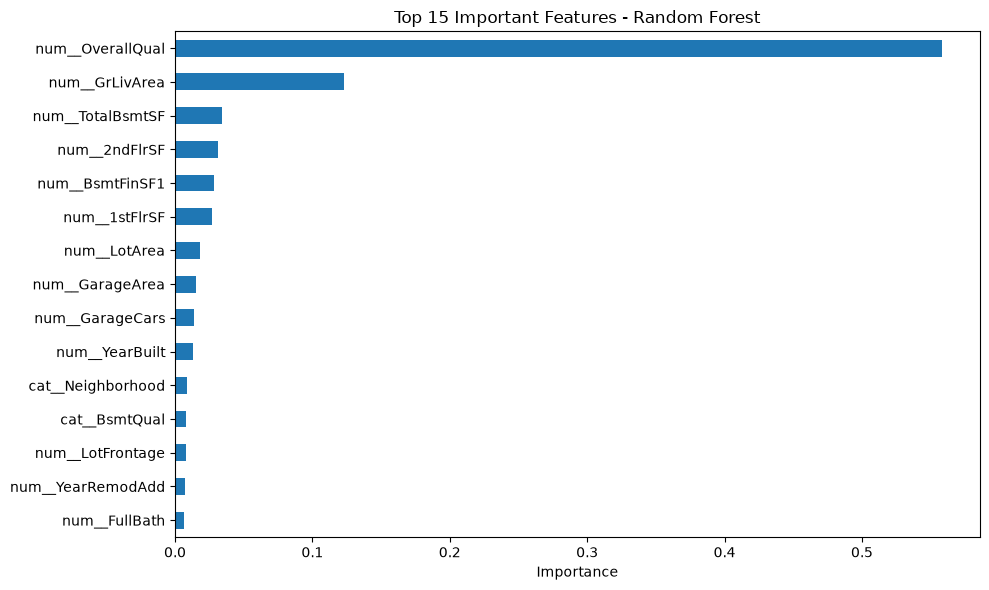

In [41]:
importance = pd.Series(
    rf.feature_importances_,
    index=preprocessor.get_feature_names_out()
).sort_values(ascending=False).head(15)

importance.sort_values().plot(kind="barh", figsize=(10, 6))
plt.title("Top 15 Important Features - Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

<h3>hyperparameter tunnning</h3>

In [42]:
n_estimators = [20, 60, 100, 120]
max_features = [0.2, 0.6, 1.0]
max_depth = [2, 8, None]
max_samples = [0.5, 0.75, 1.0]
bootstrap = [True, False]
min_samples_split = [2, 5]
min_samples_leaf = [1, 2]

In [43]:
param_grid = {
    "n_estimators": n_estimators,
    "max_features": max_features,
    "max_depth": max_depth,
    "max_samples": max_samples,
    "bootstrap": bootstrap,
    "min_samples_split": min_samples_split,
    "min_samples_leaf": min_samples_leaf
}

print(param_grid)

{'n_estimators': [20, 60, 100, 120], 'max_features': [0.2, 0.6, 1.0], 'max_depth': [2, 8, None], 'max_samples': [0.5, 0.75, 1.0], 'bootstrap': [True, False], 'min_samples_split': [2, 5], 'min_samples_leaf': [1, 2]}


In [51]:
from sklearn.metrics import make_scorer, root_mean_squared_log_error

rmsle_scorer = make_scorer(
    root_mean_squared_log_error,
    greater_is_better=False
)

In [52]:
from sklearn.model_selection import RandomizedSearchCV

rf = RandomForestRegressor(random_state=42)

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=30,
    cv=5,
     scoring=rmsle_scorer,
    random_state=42,
    n_jobs=-1,
    verbose=1
)
random_search.fit(X_train_processed, y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


C:\Users\Nitro\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
85 fits failed out of a total of 150.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
85 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\Nitro\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 851, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Nitro\anaconda3\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "C:\Users\Nitro\anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py", line 412, in fit
    raise ValueError

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'bootstrap': [True, False], 'max_depth': [2, 8, ...], 'max_features': [0.2, 0.6, ...], 'max_samples': [0.5, 0.75, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",make_scorer(r...hod='predict')
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a fu

In [53]:
random_search.best_params_

{'n_estimators': 120,
 'min_samples_split': 2,
 'min_samples_leaf': 2,
 'max_samples': 0.75,
 'max_features': 1.0,
 'max_depth': None,
 'bootstrap': True}

In [54]:
random_search.best_score_

np.float64(-0.1460903910105052)

In [55]:
print("Best CV RMSLE:", -random_search.best_score_)

Best CV RMSLE: 0.1460903910105052


In [56]:
import numpy as np
from sklearn.metrics import root_mean_squared_log_error

best_rf = random_search.best_estimator_

y_pred_best = best_rf.predict(X_valid_processed)
y_pred_best = np.maximum(y_pred_best, 0)

tuned_rmsle = root_mean_squared_log_error(
    y_valid,
    y_pred_best
)

print("Original Validation RMSLE:", rmsle_rf)
print("Tuned Validation RMSLE:", tuned_rmsle)

Original Validation RMSLE: 0.15326415267045593
Tuned Validation RMSLE: 0.15408264063181845


In [57]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import root_mean_squared_log_error
import numpy as np

model_gb = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    min_samples_leaf=2,
    random_state=42
)

model_gb.fit(X_train_processed, y_train)

y_pred_gb = model_gb.predict(X_valid_processed)
y_pred_gb = np.maximum(y_pred_gb, 0)

rmsle_gb = root_mean_squared_log_error(
    y_valid,
    y_pred_gb
)

print("Original Random Forest RMSLE:", rmsle_rf)
print("Tuned Random Forest RMSLE:", tuned_rmsle)
print("Gradient Boosting RMSLE:", rmsle_gb)

Original Random Forest RMSLE: 0.15326415267045593
Tuned Random Forest RMSLE: 0.15408264063181845
Gradient Boosting RMSLE: 0.13956674802678545


In [58]:
param_dist_gb = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4, 5],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "max_features": [None, "sqrt", 0.7]
}

In [59]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV

gb = GradientBoostingRegressor(random_state=42)

random_search_gb = RandomizedSearchCV(
    estimator=gb,
    param_distributions=param_dist_gb,
    n_iter=30,
    scoring=rmsle_scorer,
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search_gb.fit(X_train_processed, y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",GradientBoost...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'learning_rate': [0.01, 0.03, ...], 'max_depth': [2, 3, ...], 'max_features': [None, 'sqrt', ...], 'min_samples_leaf': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",make_scorer(r...hod='predict')
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be

In [60]:
print("Best Parameters:", random_search_gb.best_params_)
print("Best CV RMSLE:", -random_search_gb.best_score_)

Best Parameters: {'subsample': 1.0, 'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 4, 'learning_rate': 0.05}
Best CV RMSLE: 0.12925668806068916


In [61]:
import numpy as np
from sklearn.metrics import root_mean_squared_log_error

best_gb = random_search_gb.best_estimator_

y_pred_gb_tuned = best_gb.predict(X_valid_processed)
y_pred_gb_tuned = np.maximum(y_pred_gb_tuned, 0)

tuned_gb_rmsle = root_mean_squared_log_error(
    y_valid,
    y_pred_gb_tuned
)

print("Original Random Forest:", rmsle_rf)
print("Original Gradient Boosting:", rmsle_gb)
print("Tuned Gradient Boosting:", tuned_gb_rmsle)
print("Best CV RMSLE:", -random_search_gb.best_score_)

Original Random Forest: 0.15326415267045593
Original Gradient Boosting: 0.13956674802678545
Tuned Gradient Boosting: 0.14012090995994733
Best CV RMSLE: 0.12925668806068916


In [62]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [63]:
from xgboost import XGBRegressor
import numpy as np
from sklearn.metrics import root_mean_squared_log_error

model_xgb = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=3,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

model_xgb.fit(X_train_processed, y_train)

y_pred_xgb = model_xgb.predict(X_valid_processed)
y_pred_xgb = np.maximum(y_pred_xgb, 0)

rmsle_xgb = root_mean_squared_log_error(
    y_valid,
    y_pred_xgb
)

print("Original Random Forest:", rmsle_rf)
print("Original Gradient Boosting:", rmsle_gb)
print("Tuned Gradient Boosting:", tuned_gb_rmsle)
print("XGBoost RMSLE:", rmsle_xgb)

Original Random Forest: 0.15326415267045593
Original Gradient Boosting: 0.13956674802678545
Tuned Gradient Boosting: 0.14012090995994733
XGBoost RMSLE: 0.13474445044994354


In [64]:
param_dist_xgb = {
    "n_estimators": [300, 500, 800, 1000],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4, 5],
    "min_child_weight": [1, 3, 5, 7],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "reg_alpha": [0, 0.01, 0.1, 1],
    "reg_lambda": [1, 5, 10]
}

In [65]:
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV

xgb = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=1
)

random_search_xgb = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_dist_xgb,
    n_iter=30,
    scoring=rmsle_scorer,
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search_xgb.fit(X_train_processed, y_train)

print("Best Parameters:", random_search_xgb.best_params_)
print("Best CV RMSLE:", -random_search_xgb.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters: {'subsample': 0.7, 'reg_lambda': 5, 'reg_alpha': 0, 'n_estimators': 1000, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 0.6}
Best CV RMSLE: 0.12818540781736373


In [66]:
from sklearn.metrics import root_mean_squared_log_error
import numpy as np

# Get the best model found by RandomizedSearchCV
best_xgb = random_search_xgb.best_estimator_

# Predict on the same validation set
y_pred_xgb_tuned = best_xgb.predict(X_valid_processed)

# RMSLE requires non-negative predictions
y_pred_xgb_tuned = np.maximum(y_pred_xgb_tuned, 0)

# Calculate validation RMSLE
rmsle_xgb_tuned = root_mean_squared_log_error(
    y_valid,
    y_pred_xgb_tuned
)

print("Tuned XGBoost Validation RMSLE:", rmsle_xgb_tuned)

Tuned XGBoost Validation RMSLE: 0.14184436202049255


In [67]:
print("Original XGBoost RMSLE:", rmsle_xgb)
print("Tuned XGBoost RMSLE:", rmsle_xgb_tuned)

if rmsle_xgb_tuned < rmsle_xgb:
    print("Tuned XGBoost performs better!")
else:
    print("Original XGBoost performs better on this validation set.")

Original XGBoost RMSLE: 0.13474445044994354
Tuned XGBoost RMSLE: 0.14184436202049255
Original XGBoost performs better on this validation set.


In [68]:
# Preprocessor ko poore training data par fit karo
X = train.drop(columns=["SalePrice", "Id"])
y = train["SalePrice"]

X_test = test.drop(columns=["Id"])

X_processed = preprocessor.fit_transform(X)
X_test_processed = preprocessor.transform(X_test)

# Original XGBoost model
from xgboost import XGBRegressor

final_model = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=3,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Train on all available training data
final_model.fit(X_processed, y)

print("Final model trained successfully!")

Final model trained successfully!


In [69]:
predictions = final_model.predict(X_test_processed)

# House prices should not be negative
predictions = predictions.clip(min=0)

print(predictions[:10])
print("Total predictions:", len(predictions))

[124430.34 165700.81 179999.16 194635.34 185707.83 175669.08 173813.16
 166983.36 176480.95 128633.08]
Total predictions: 1459


In [70]:
from sklearn.metrics import root_mean_squared_log_error
import numpy as np

# Original XGBoost model ki validation predictions
y_pred = model_xgb.predict(X_valid_processed)

# Negative predictions remove karo
y_pred = np.maximum(y_pred, 0)

# RMSLE calculate karo
rmsle = root_mean_squared_log_error(y_valid, y_pred)

print("Validation RMSLE:", rmsle)
print("Validation RMSLE (%):", round(rmsle * 100, 2), "%")
print("Approximate score:", round((1 - rmsle) * 100, 2), "%")

Validation RMSLE: 0.13474445044994354
Validation RMSLE (%): 13.47 %
Approximate score: 86.53 %


In [71]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(y_valid, y_pred)
rmse = np.sqrt(mean_squared_error(y_valid, y_pred))

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

comparison = pd.DataFrame({
    "Actual Price": y_valid,
    "Predicted Price": y_pred
})

comparison["Difference"] = (
    comparison["Actual Price"] - comparison["Predicted Price"]
).abs()

print(comparison.head(10).round(2))
print("Average absolute error:", round(comparison["Difference"].mean(), 2))

MAE: 15469.43
RMSE: 24902.31
      Actual Price  Predicted Price  Difference
892         154500    144223.031250    10276.97
1105        325000    337080.093750    12080.06
413         115000    107195.179688     7804.82
522         159000    160988.000000     1988.00
1036        315500    329164.250000    13664.25
614          75500     77783.078125     2283.08
218         311500    236626.625000    74873.38
1160        146000    144836.812500     1163.19
649          84500     77865.257812     6634.74
887         135500    138374.812500     2874.81
Average absolute error: 15469.43


In [72]:
from xgboost import XGBRegressor

# Preprocessor ko full training dataset par fit karo
X = train.drop(columns=["SalePrice", "Id"])
y = train["SalePrice"]
X_test = test.drop(columns=["Id"])

X_processed = preprocessor.fit_transform(X)
X_test_processed = preprocessor.transform(X_test)

# Best validation-performing model: original XGBoost
final_model = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=3,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_processed, y)

print("Final model trained on all training data!")

Final model trained on all training data!


In [73]:
predictions = final_model.predict(X_test_processed)

# Negative prices ko 0 kar do
predictions = predictions.clip(min=0)

print("First 10 predictions:")
print(predictions[:10])

print("Total predictions:", len(predictions))

First 10 predictions:
[124430.34 165700.81 179999.16 194635.34 185707.83 175669.08 173813.16
 166983.36 176480.95 128633.08]
Total predictions: 1459


In [74]:
import pandas as pd

submission = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": predictions
})

submission.to_csv("submission.csv", index=False)

print(submission.head())
print("Submission file created!")

     Id      SalePrice
0  1461  124430.343750
1  1462  165700.812500
2  1463  179999.156250
3  1464  194635.343750
4  1465  185707.828125
Submission file created!


In [75]:
import os

print("Current folder:", os.getcwd())
print("Files:", os.listdir())

Current folder: C:\Users\Nitro\House Prediction Model
Files: ['.ipynb_checkpoints', 'Output.html', 'price_prediction.ipynb', 'submission.csv', 'test.csv', 'train.csv']


In [76]:
submission.to_csv("submission.csv", index=False)

In [77]:
import os

print(os.path.abspath("submission.csv"))
print("CSV created:", os.path.exists("submission.csv"))

C:\Users\Nitro\House Prediction Model\submission.csv
CSV created: True
